[All milestones](../START_HERE.ipynb) · [Main solution](../solution/reduced_qubit_hybrid_hourly.ipynb)

# Milestone 5 — hardware and simulator evidence

**Real hardware completed on Rigetti Cepheus**, using the warm-start reduced-qubit hourly variant for 5 and 10 plants. The original assignment specifies IonQ and an eight-qubit hourly problem: this is a hardware/method substitution, not literal completion of that device-specific requirement.

The earlier IonQ noisy-simulator study and the later Rigetti warm-start experiment are separate comparisons. These cells only read saved evidence; they do not submit jobs. Job IDs, costs, timings, and validation are retained in `results/`.

In [1]:
# Resolve data and shared helpers when opening a notebook from its own folder.
from pathlib import Path
import os
import sys
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'src/check.py').is_file() and (p / 'data').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook inside the cloned project.')
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
os.chdir(PROJECT_ROOT)


Local ideal: 200 shots; feasible 55.5%; best hourly commitment 13.0%
IonQ noisy simulator: 200 shots; feasible 49.5%; best hourly commitment 8.0%


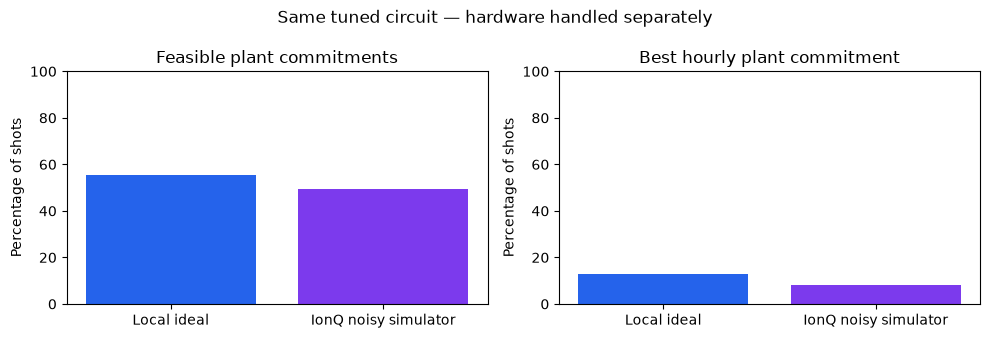

training beta shift -0.1 ionq:ionq:sim:simulator-69e6-qjob-6af97144e538ce0882fae135 cost: 0.0 credits; created-to-ended: 3.54 s
training beta shift +0.0 ionq:ionq:sim:simulator-69e6-qjob-6af97154e538ce0882fae144 cost: 0.0 credits; created-to-ended: 3.574 s
training beta shift +0.1 ionq:ionq:sim:simulator-69e6-qjob-6af97166e538ce0882fae162 cost: 0.0 credits; created-to-ended: 3.414 s
independent final noisy readout ionq:ionq:sim:simulator-69e6-qjob-6af97176e538ce0882fae16f cost: 0.0 credits; created-to-ended: 3.272 s
Hardware status: Managed separately by the user’s other agent; no QPU submitted by this agent.


In [2]:
# Offline plot: loading saved evidence does not submit or poll jobs.
import json
from pathlib import Path
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
from check import load_plants,load_demand,check_hour,hour_ok
audit = json.loads(Path('results/milestone_audit.json').read_text())
hw = audit['hardware']
assert hw['hourly_qubo_verified']
plants = load_plants(); demand,reserve=load_demand()
history=np.asarray(hw['history']);on,off=hw['must_on'],hw['must_off']
hour_check=check_hour(plants,demand[14],reserve[14],history[-1],was_on=history[-1],
                      must_on=on,must_off=off,verbose=False)
best_index=int(np.dot(hour_check['best_choice'],2**np.arange(5)))
valid=np.array([hour_ok(plants,demand[14],reserve[14],[(k>>i)&1 for i in range(5)],on,off)
                for k in range(32)])
series={'Local ideal':hw['tuned_ideal_counts'],
        'IonQ noisy simulator':hw['noise_tuning']['holdout_counts']}
if hw.get('hardware_counts'):series['IonQ QPU']=hw['hardware_counts']
shares={}
for label,counts in series.items():
    share=np.zeros(32)
    for key,count in counts.items():share[int(key.replace(' ',''),2)&31]+=count/sum(counts.values())
    shares[label]=share
    print(f'{label}: {sum(counts.values())} shots; feasible {100*share[valid].sum():.1f}%; '
          f'best hourly commitment {100*share[best_index]:.1f}%')
fig,axes=plt.subplots(1,2,figsize=(10,3.4))
axes[0].bar(list(shares),[100*v[valid].sum() for v in shares.values()],color=['#2563eb','#7c3aed','#16a34a'][:len(shares)])
axes[1].bar(list(shares),[100*v[best_index] for v in shares.values()],color=['#2563eb','#7c3aed','#16a34a'][:len(shares)])
axes[0].set(title='Feasible plant commitments',ylabel='Percentage of shots',ylim=(0,100))
axes[1].set(title='Best hourly plant commitment',ylabel='Percentage of shots',ylim=(0,100))
fig.suptitle('Same tuned circuit — hardware handled separately' if not hw.get('hardware_counts') else 'Same tuned circuit — simulator vs QPU')
fig.tight_layout();plt.show()
for row in hw['noise_tuning']['jobs']:
    stamps=row['metadata']['timeStamps']
    elapsed=(datetime.fromisoformat(stamps['endedAt'].replace('Z','+00:00'))-
             datetime.fromisoformat(stamps['createdAt'].replace('Z','+00:00'))).total_seconds()
    print(row['phase'],row['job_id'],'cost:',row['metadata'].get('cost'),
          'credits; created-to-ended:',round(elapsed,3),'s')
print('Hardware status:',hw['hardware_status'])


<a id="warm-start-hardware-comparison"></a>
## Selected hardware method — warm-start Reduced Qubit Hybrid Hourly

**The five- and ten-plant hardware comparison uses the warm-start variant.** The RQ 1–RQ 5 study uses the original reduced-hourly protocol.

The warm-start method first removes only legally forced plant decisions. A cheap classical merit-order heuristic then supplies a feasible hourly starting row. Free plant bits are biased toward that row, and QAOA uses nonzero cost evolution and a mixer matched to the initial state. The cheapest feasible candidate must appear in the fresh final measurements; the starting row is never silently substituted for a hardware result.

Use gross demand, no solar/wind, p=1, hours 13–17, six angle candidates with 256 simulation training shots each, and 200 fresh final shots per hour. For hardware, train the angles in simulation for the current history, then execute the chosen circuit on the QPU. Compare hardware and ideal simulation on identical circuits and shot counts; keep any full-day trajectories separately identified. The existing initial MILP and conditional tail MILP remain part of the hybrid.

**Simulation finding:** Warm-started reduced-qubit QAOA achieved a valid 100-plant schedule within **0.059% of the MILP optimum** in simulation; classical controls matched or improved this result.

The setup below exposes the existing warm-start implementation without submitting jobs. The final cell displays **saved local Aer MPS simulation results**, not hardware measurements or a new run. Completed QPU results are shown in the hardware section below.


## Real QPU results — warm-start 5- and 10-plant comparison

Device: **Rigetti Cepheus-1-108Q through Amazon Braket**, accessed with qBraid. This section uses the selected greedy warm start and aligned mixer, not the older original-QAOA milestone circuit. Angles are trained locally on six candidates (256 simulated shots each); the selected circuit receives 200 fresh **physical QPU shots** per hour. Hours 13–17 adapt to the preceding measured choices. Gross demand only; no solar/wind.

The first bar chart compares full-day cost gaps for independently evolving simulation and hardware schedules. The second uses the **identical hardware circuits and histories**, comparing their ideal feasible probabilities with measured hardware outcomes. Both hybrids retain the MILP prefix and tail. One trial per fleet is a hardware demonstration, not a reliability study or quantum-advantage claim.

The following cell only reads saved results and draws the chart; it cannot submit another job.


| Plants | Simulation gap | Hardware status | Hardware gap | Feasible QPU shots |
|---:|---:|:---|---:|---:|
| 5 | 0.0000% | COMPLETED | 0.0000% | 251/1000 |
| 10 | 0.0101% | COMPLETED | 1.5265% | 118/1000 |

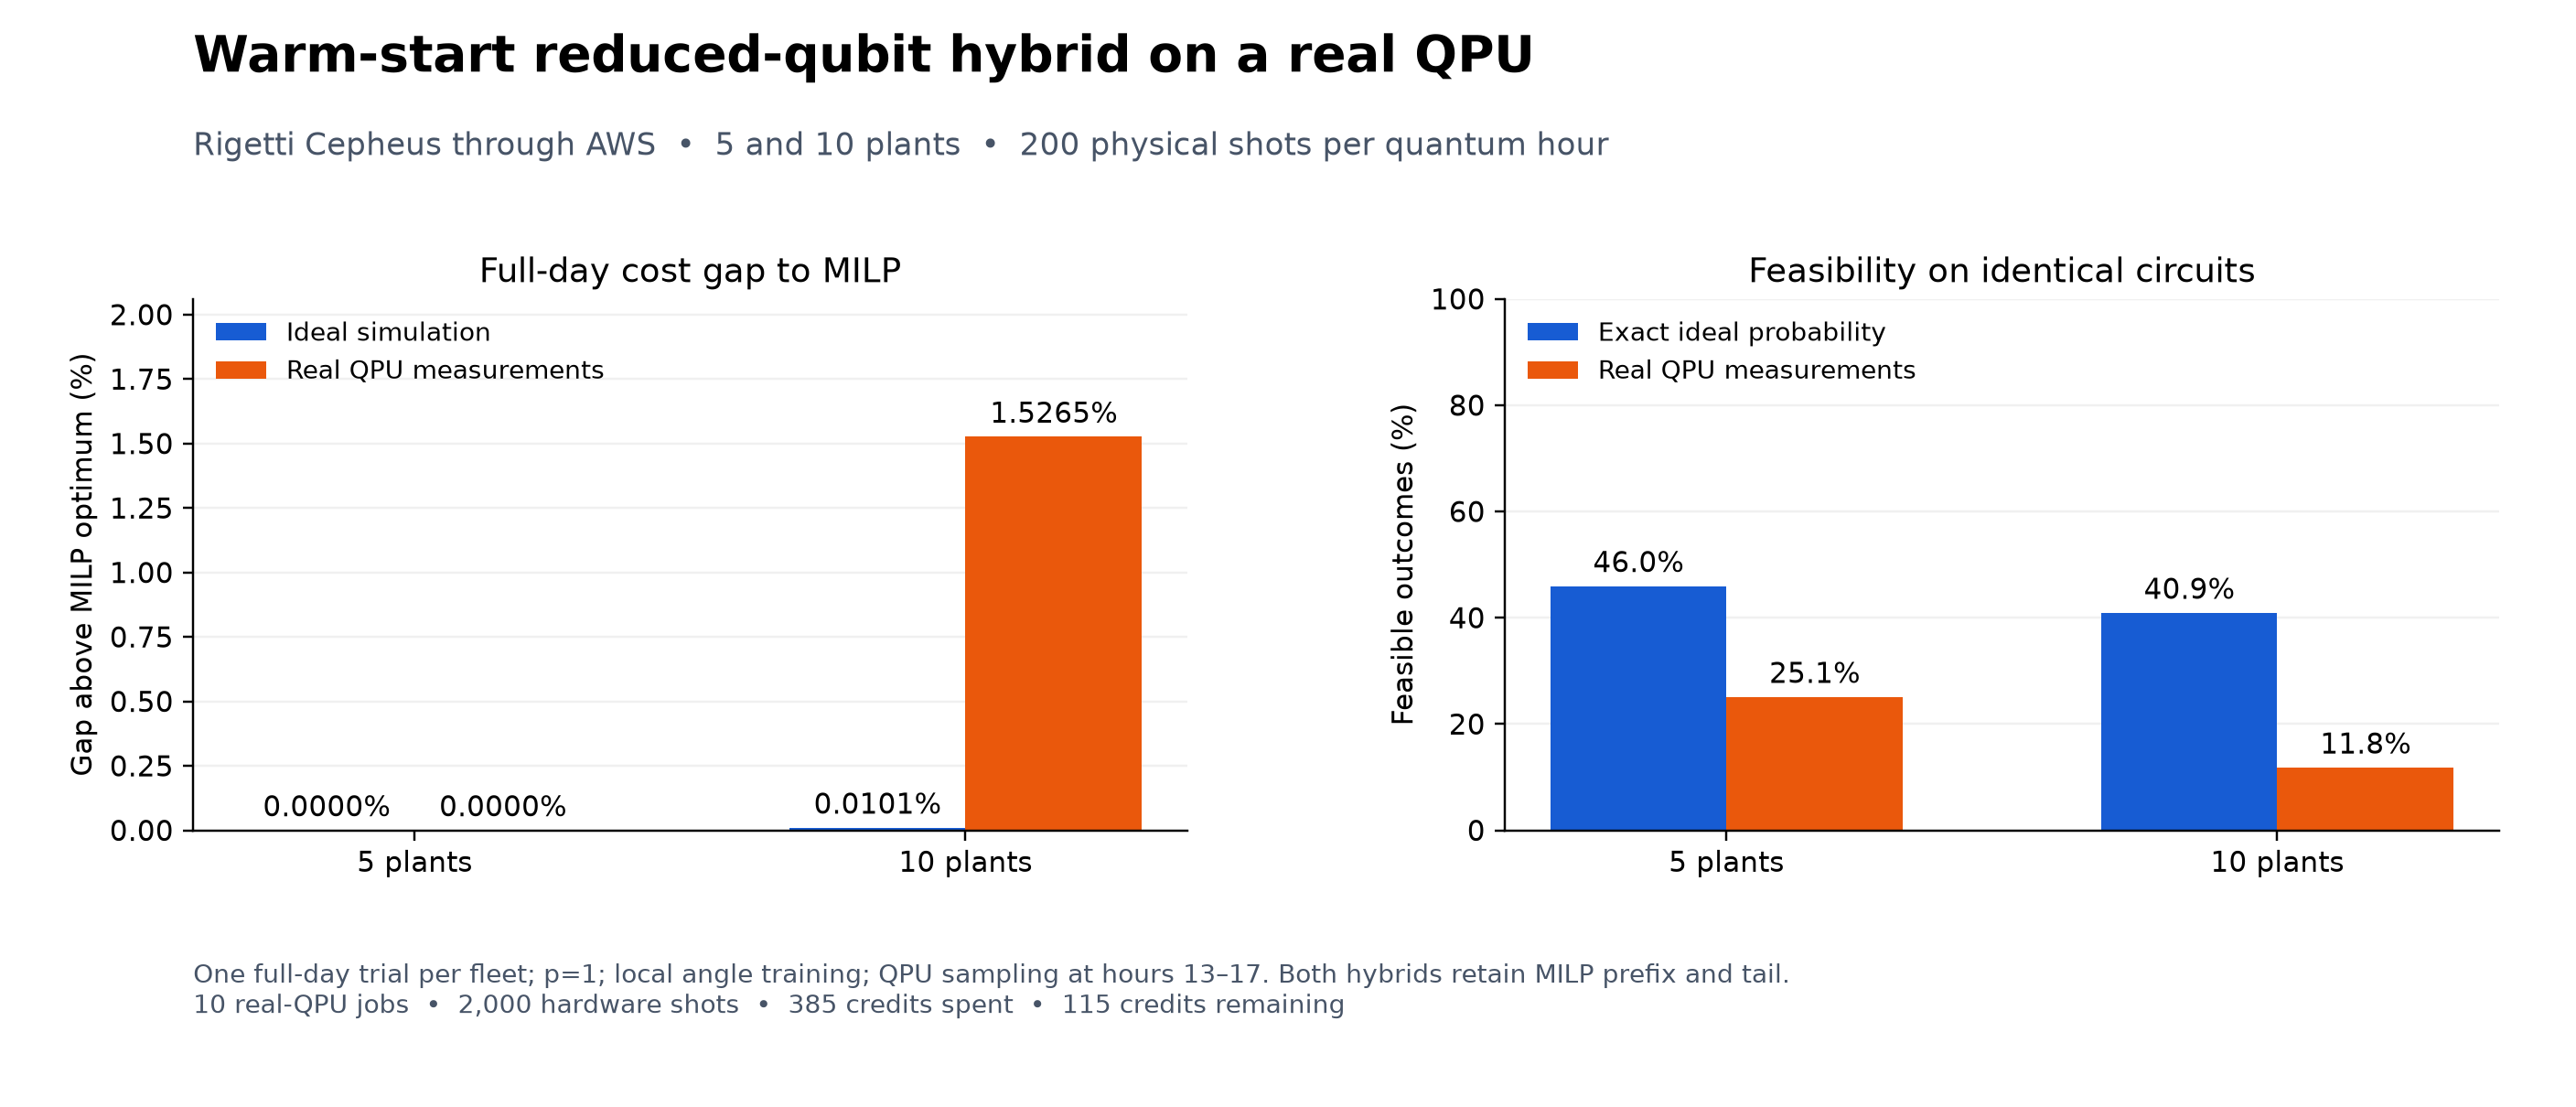

**Real device:** `aws:rigetti:qpu:cepheus-1-108q`

**QPU job IDs:**

- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af9748be538ce0882fae20e` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af974c4e538ce0882fae21f` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af974dfe538ce0882fae22d` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af97519e538ce0882fae28b` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af97552e538ce0882fae2a1` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af9758ce538ce0882fae2b7` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af975c5e538ce0882fae2c4` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af975ffe538ce0882fae2d5` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af97638e538ce0882fae2e4` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af97654e538ce0882fae2f3` — COMPLETED

In [3]:
# READ-ONLY: saved real-QPU results; no submissions or paid actions.
from pathlib import Path
import json
from IPython.display import display, Markdown, Image
warm_hardware_result_dir = Path('results/warm_start_hardware/20261115T085833206497Z')
warm_hardware_results = json.loads((warm_hardware_result_dir / 'experiment.json').read_text())
lines = ['| Plants | Simulation gap | Hardware status | Hardware gap | Feasible QPU shots |',
         '|---:|---:|:---|---:|---:|']
for fleet, run in warm_hardware_results['fleets'].items():
    hw = run['hardware']; done = [t for t in hw['hourly'] if 'hardware' in t]
    gap = hw.get('checked', {}).get('gap_pct')
    gap_text = '—' if gap is None else f'{gap:.4f}%'
    lines.append(f"| {fleet} | {run['simulation']['checked']['gap_pct']:.4f}% | {hw['status']} | {gap_text} | "
                 f"{sum(t['hardware']['valid_shots'] for t in done)}/{len(done)*200} |")
display(Markdown('\n'.join(lines)))
display(Image(filename=str(warm_hardware_result_dir / 'hardware_vs_simulation.png')))
display(Markdown('**Real device:** `' + warm_hardware_results['device'] + '`\n\n' +
    '**QPU job IDs:**\n\n' + '\n'.join('- `' + j['job_id'] + '` — ' + j['status'] for j in warm_hardware_results['jobs'])))


In [4]:
from IPython.display import display, Markdown
display(Markdown((warm_hardware_result_dir / 'REPORT.md').read_text()))

# Warm-start reduced hourly method: real hardware demonstration

| Plants | Ideal daily gap | Hardware status | Hardware daily gap | Hardware feasible shots |
|---:|---:|:---|---:|---:|
| 5 | 0.0000% | COMPLETED | 0.0000% | 251/1000 |
| 10 | 0.0101% | COMPLETED | 1.5265% | 118/1000 |

![Hardware comparison](hardware_vs_simulation.png)

Device: `aws:rigetti:qpu:cepheus-1-108q`. This is the selected greedy-warm-start p=1 reduced hourly QAOA with biased initialization and its matching mixer. Angles are selected from six candidates using 256 local simulated training shots each; final candidates are measured on the real QPU under the user's 500-credit instruction and a tighter 385-credit execution cap. Demand, reserve, min-up/down locks, economic dispatch, datasets and the MILP reference match the ideal simulation. Both schedulers retain the initial full-day MILP and conditional tail. No solar, wind, block refinement, unsampled repair or post-hoc bit reversal. AWS-path counts use classical bit 0 on the right, as documented by qBraid.

The daily-gap bars compare independent complete trajectories with the same protocol. The feasibility bars compare hardware measurements against exact ideal probabilities for the very same hardware circuits/histories. One trial per fleet does not estimate repeated-run reliability. Invalid or unfinished days have no reported cost gap.

## Submission plan

Up to 10 jobs: five sequential quantum hours per fleet, 200 shots each. Current quote: 38.50 credits/job, maximum 385.00 qBraid credits. No extra paid calibration/training jobs; no automatic paid retries. Each new submission checks the price and the approved cumulative ceiling. Existing job IDs are resumed instead of resubmitted. A failed or infeasible hardware result remains a failure.

Raw counts, payloads, source/data hashes, settings, job IDs and costs are saved in `experiment.json` and per-job files. `submission_plan.json` records the plan before hardware submission.

Sources: [qBraid AWS execution and bit ordering](https://docs.qbraid.com/v2/sdk/user-guide/providers/aws), [Rigetti submission paths](https://docs.qbraid.com/v2/sdk/user-guide/providers/rigetti).

## Verified execution and billing

All ten jobs completed on the real Rigetti QPU. Independent replay verified all 2,000 raw hardware shots, the cost-preserving reduced encoding on observed samples, both full-day schedules, and that every selected quantum-hour row occurred in the actual QPU counts. No failed outcome was replaced by a simulated or unsampled choice.

Provider-reported charges total **385 credits**. The account balance after completion was **115 credits**. `provider_execution_evidence.json` records the service-confirmed device, completion state and timestamps; each job also has its native compiled Quil program and readout mapping.

| Plants | Ideal full-day gap | Real-QPU full-day gap | Feasible QPU samples |
|---:|---:|---:|---:|
| 5 | 0.0000% | 0.0000% | 251/1000 |
| 10 | 0.0101% | 1.5265% | 118/1000 |

The 5-plant hardware schedule matches the MILP optimum. The 10-plant hardware schedule is valid but more expensive than its ideal-simulation counterpart. Hardware returned fewer feasible candidates on the identical circuits; finite sampling and hardware imperfections can affect these results. This single pilot does not isolate every error source or establish quantum advantage.

For presentation: **A warm-start reduced-qubit hybrid produced valid schedules on a real Rigetti QPU, achieving 0% and 1.53% gaps to MILP for 5 and 10 plants, respectively.**
